### Library Importation

In [ ]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import itertools

from pathlib import Path
from PIL import Image

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### Load dataset

In [ ]:
# Path to CSV files
data_path = Path("../data")

# Load datasets
train_df = pd.read_csv(data_path / "train.csv")
validation_df = pd.read_csv(data_path / "validation.csv")
test_df = pd.read_csv(data_path / "test.csv")

# Display dataset sizes
print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Testing:", len(test_df))

In [ ]:
# Display first five training records
train_df.head()

In [4]:
def load_images(dataframe):

    images = []

    for image_path in dataframe["image_path"]:

        image = Image.open(image_path).convert("RGB")

        image_array = np.array(image)

        images.append(image_array)

    return np.array(images)


# Load images
X_train = load_images(train_df)
X_val = load_images(validation_df)
X_test = load_images(test_df)

# Load labels
y_train = train_df["label"].values
y_val = validation_df["label"].values
y_test = test_df["label"].values

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (5806, 128, 128, 3)
Validation shape: (1659, 128, 128, 3)
Testing shape: (830, 128, 128, 3)


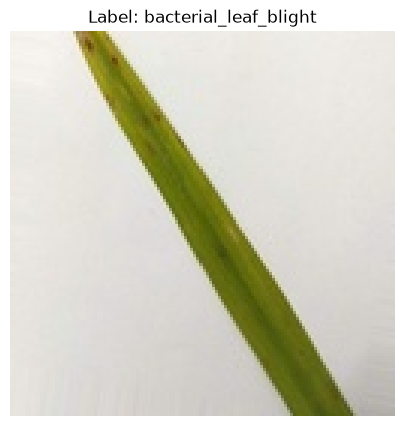

In [5]:
plt.figure(figsize=(5, 5))

plt.imshow(X_train[random.randint(0, 1000)])
plt.title(f"Label: {y_train[0]}")
plt.axis("off")

plt.show()

In [6]:
# Get the number of images
n_train = X_train.shape[0]
n_val = X_val.shape[0]
n_test = X_test.shape[0]

# Flatten images
X_train_flat = X_train.reshape(n_train, -1)
X_val_flat = X_val.reshape(n_val, -1)
X_test_flat = X_test.reshape(n_test, -1)

# Display shapes
print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)
print("Testing:", X_test_flat.shape)

Training: (5806, 49152)
Validation: (1659, 49152)
Testing: (830, 49152)


### Feature Scaling

In [7]:
# Convert pixel values to float and normalize (feature scaling)
X_train_scaled = X_train_flat.astype(np.float32) / 255.0
X_val_scaled = X_val_flat.astype(np.float32) / 255.0
X_test_scaled = X_test_flat.astype(np.float32) / 255.0

# Check values
print("Minimum:", X_train_scaled.min())
print("Maximum:", X_train_scaled.max())

Minimum: 0.0
Maximum: 1.0


### Dimensional Deduction PCA Unsupervised Learing

In [8]:
# Select the number of components
n_components = 25

# Create PCA model of Unsupervised Learning
pca_model = PCA(
    n_components=n_components,
    random_state=42
)

# Fit PCA using training data only
pca_model.fit(X_train_scaled)

print("PCA training completed!")

PCA training completed!


In [9]:
# Get explained variance ratio
explained_variance = pca_model.explained_variance_ratio_

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print("Variance explained by first 10 components:")

for i in range(min(5, len(explained_variance))):
    print(
        f"PC{i + 1}: {explained_variance[i]:.4f}"
    )

print(
    "\nTotal variance explained:",
    cumulative_variance[-1]
)

Variance explained by first 10 components:
PC1: 0.6094
PC2: 0.0675
PC3: 0.0303
PC4: 0.0219
PC5: 0.0210

Total variance explained: 0.87777555


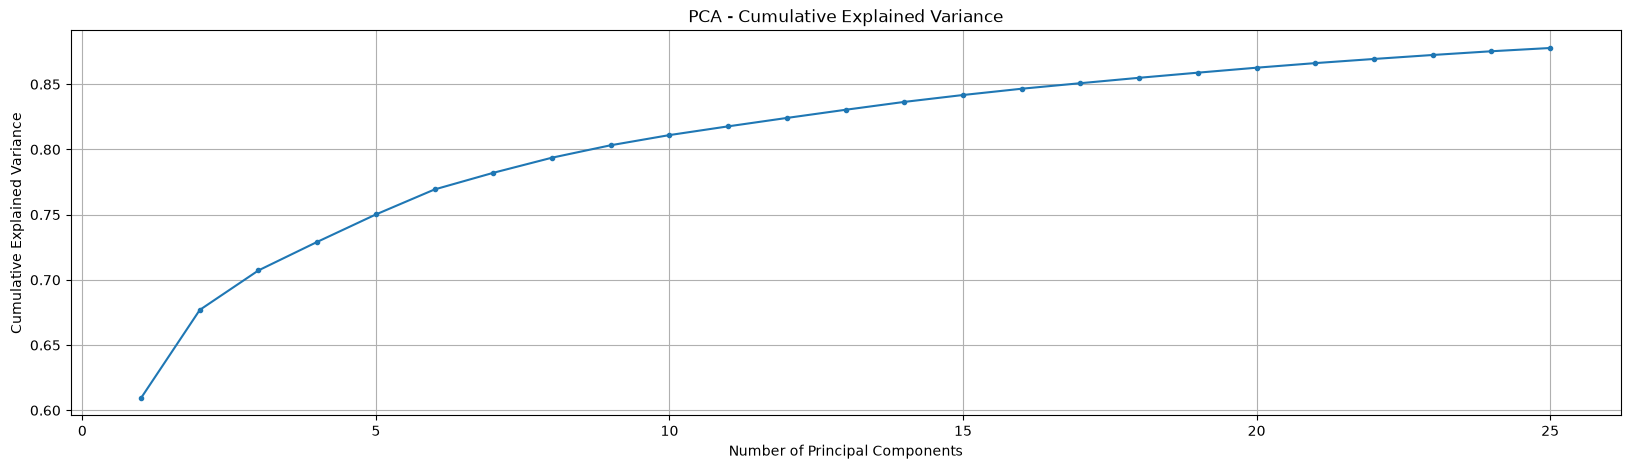

In [10]:
plt.figure(figsize=(20, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="."
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.grid()
plt.show()

In [11]:
# Transform datasets to PCA
X_train_pca = pca_model.transform(X_train_scaled)
X_val_pca = pca_model.transform(X_val_scaled)
X_test_pca = pca_model.transform(X_test_scaled)

# Display new dimensions
print("Training PCA shape:", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

Training PCA shape: (5806, 25)
Validation PCA shape: (1659, 25)
Testing PCA shape: (830, 25)


### Random Architectures to find best one

In [12]:
# # Random Architectures to find best one
# layers = [1, 2, 3, 4, 5, 6]
# neural = [16, 32, 64, 128, 256, 384, 512, 768]

# # Generate combinations with replacement (allowing repetition)
# combos_rep = []
# for L in layers:
#     combos_rep.extend(itertools.combinations_with_replacement(neural, L))

# nn_configs = {f"NN-{i:03d}": c for i, c in enumerate(combos_rep, 1)}

# # Example usage:
# print(f"Total configurations (with repetition): {len(nn_configs)}")
# print("NN-001:", nn_configs["NN-001"])
# print("NN-486:", nn_configs["NN-486"])
# nn_configs

In [13]:
# results = []

# models = {}

# for name, layers in nn_configs.items():

#     print(f"Training {name}: {layers}")

#     model = MLPClassifier(
#         hidden_layer_sizes=layers,
#         activation="relu",
#         solver="adam",
#         max_iter=300,
#         learning_rate_init=0.001,
#         random_state=42,
#         early_stopping=True,
#         validation_fraction=0.1
#     )

#     model.fit(X_train_pca, y_train)

#     y_pred = model.predict(X_val_pca)

#     accuracy = accuracy_score(y_val, y_pred)

#     results.append({
#         "Model": name,
#         "Hidden Layers": str(layers),
#         "Validation Accuracy": accuracy * 100,
#         "Training Iterations": model.n_iter_
#     })

#     models[name] = model

#     print(f"Validation Accuracy: {accuracy * 100:.2f}%")
#     print("-" * 40)

In [14]:
# results.sort(key=lambda x: x['Validation Accuracy'], reverse=True)
# results

### Neural Network Classification Supervised Learning

In [15]:
# Best choice 82.xx% (512, 256, 256, 128, 64)
nn_model = MLPClassifier(
    hidden_layer_sizes=(512, 256, 256, 128, 64),
    activation="relu",
    solver="adam",
    max_iter=100,
    random_state=42,
)

print("Neural Network model created!")

Neural Network model created!


In [16]:
nn_model.fit(X_train_pca, y_train)

print("Neural Network training completed!")

Neural Network training completed!


In [17]:
# Evalue on training set
y_train_pred_nn = nn_model.predict(X_train_pca)

nn_accuracy = accuracy_score(y_train, y_train_pred_nn)

print(f"Neural Network Validation Accuracy: {nn_accuracy * 100:.2f}%")
print(classification_report(y_train, y_train_pred_nn))

# Display first 10 predictions
for i in range(10):
    print(
        f"Actual: {y_train[i]} | "
        f"Predicted: {y_train_pred_nn[i]}"
    )

Neural Network Validation Accuracy: 99.69%
                       precision    recall  f1-score   support

bacterial_leaf_blight       1.00      1.00      1.00      1161
           brown_spot       0.99      1.00      0.99      1162
              healthy       1.00      0.99      1.00      1161
           rice_blast       1.00      0.99      0.99      1161
       tungro_disease       1.00      1.00      1.00      1161

             accuracy                           1.00      5806
            macro avg       1.00      1.00      1.00      5806
         weighted avg       1.00      1.00      1.00      5806

Actual: bacterial_leaf_blight | Predicted: bacterial_leaf_blight
Actual: brown_spot | Predicted: brown_spot
Actual: healthy | Predicted: healthy
Actual: tungro_disease | Predicted: tungro_disease
Actual: rice_blast | Predicted: rice_blast
Actual: tungro_disease | Predicted: tungro_disease
Actual: bacterial_leaf_blight | Predicted: bacterial_leaf_blight
Actual: healthy | Predicted: hea

In [18]:
# Evalue on validation set
y_val_pred_nn = nn_model.predict(X_val_pca)

nn_accuracy = accuracy_score(y_val, y_val_pred_nn)

print(f"Neural Network Validation Accuracy: {nn_accuracy * 100:.2f}%")
print(classification_report(y_val, y_val_pred_nn))

# Display first 10 predictions
for i in range(10):
    print(
        f"Actual: {y_val[i]} | "
        f"Predicted: {y_val_pred_nn[i]}"
    )

Neural Network Validation Accuracy: 88.37%
                       precision    recall  f1-score   support

bacterial_leaf_blight       0.94      0.93      0.94       332
           brown_spot       0.85      0.91      0.88       331
              healthy       0.84      0.82      0.83       332
           rice_blast       0.79      0.76      0.77       332
       tungro_disease       0.99      1.00      1.00       332

             accuracy                           0.88      1659
            macro avg       0.88      0.88      0.88      1659
         weighted avg       0.88      0.88      0.88      1659

Actual: tungro_disease | Predicted: tungro_disease
Actual: rice_blast | Predicted: healthy
Actual: brown_spot | Predicted: brown_spot
Actual: bacterial_leaf_blight | Predicted: bacterial_leaf_blight
Actual: healthy | Predicted: healthy
Actual: bacterial_leaf_blight | Predicted: bacterial_leaf_blight
Actual: healthy | Predicted: brown_spot
Actual: tungro_disease | Predicted: tungro_dis

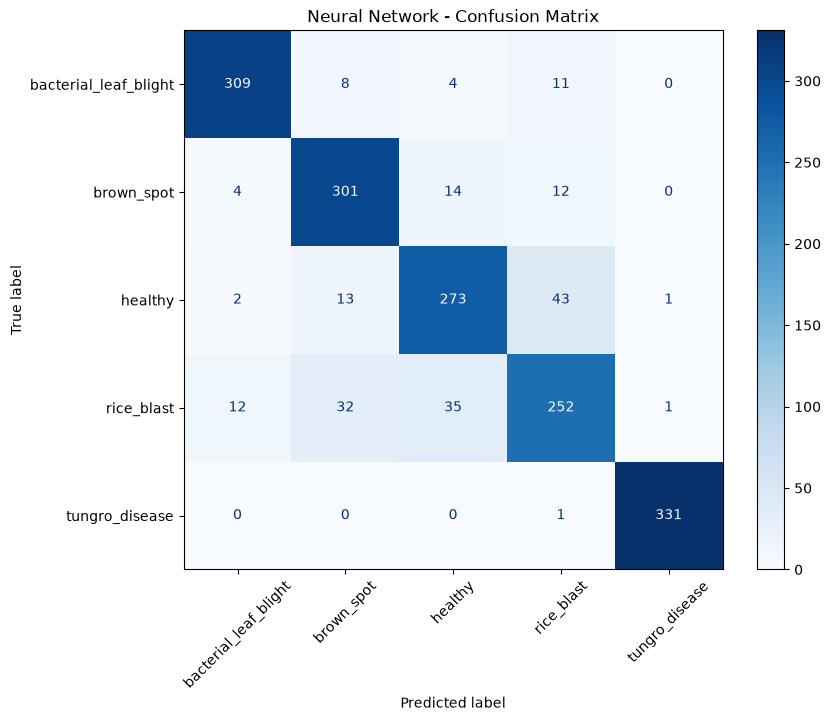

In [19]:
cm_nn = confusion_matrix(
    y_val,
    y_val_pred_nn,
    labels=nn_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn,
    display_labels=nn_model.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Neural Network - Confusion Matrix")
plt.show()